# DSCI 552 Homework 4

**Name:** Jingyu Zhang  
**GitHub Username:** jingyuz9-wq  
**USC ID:** 5744431585

In [1]:
from pathlib import Path
from io import StringIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
DATA_DIR = Path("../data/AReM")

print("Data folder exists:", DATA_DIR.exists())
print("Activity folders:", sorted(
    folder.name for folder in DATA_DIR.iterdir()
    if folder.is_dir()
))

Data folder exists: True
Activity folders: ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']


In [4]:
COLUMN_NAMES = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

def read_sensor_csv(file_path):
    lines = Path(file_path).read_text(
        encoding="utf-8"
    ).splitlines()

    data_lines = [
        line.strip().rstrip(",")
        for line in lines
        if line.strip()
        and not line.lstrip().startswith("#")
    ]

    separator = "," if "," in data_lines[0] else r"\s+"

    df = pd.read_csv(
        StringIO("\n".join(data_lines)),
        sep=separator,
        header=None,
        names=COLUMN_NAMES,
        engine="python"
    )

    return df.apply(pd.to_numeric, errors="raise")

In [5]:
test_file = DATA_DIR / "bending1" / "dataset1.csv"

df_test = read_sensor_csv(test_file)

print("Data shape:", df_test.shape)
df_test.head()

Data shape: (480, 7)


,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,39.25,0.43,22.75,0.43,33.75,1.3
1,250,39.25,0.43,23.00,0.00,33.00,0.0
2,500,39.25,0.43,23.25,0.43,33.00,0.0
3,750,39.50,0.50,23.00,0.71,33.00,0.0
4,1000,39.50,0.50,24.00,0.00,33.00,0.0


In [6]:
ACTIVITIES = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]

def get_split(activity, dataset_num):
    if activity in ["bending1", "bending2"]:
        return "test" if dataset_num in [1, 2] else "train"
    else:
        return "test" if dataset_num in [1, 2, 3] else "train"


train_files = []
test_files = []

for activity in ACTIVITIES:
    folder = DATA_DIR / activity

    for file_path in folder.glob("dataset*.csv"):
        dataset_num = int(
            file_path.stem.replace("dataset", "")
        )

        if get_split(activity, dataset_num) == "test":
            test_files.append(file_path)
        else:
            train_files.append(file_path)

print("Training instances:", len(train_files))
print("Testing instances:", len(test_files))
print("Total instances:", len(train_files) + len(test_files))

Training instances: 69
Testing instances: 19
Total instances: 88


In [7]:
SELECTED_SERIES = [1, 2, 6]

def extract_selected_features(file_path):
    df = read_sensor_csv(file_path)
    features = {}

    for series_num in SELECTED_SERIES:
        column_name = COLUMN_NAMES[series_num]
        series = df[column_name]

        features[f"mean{series_num}"] = series.mean()
        features[f"std{series_num}"] = series.std()
        features[f"max{series_num}"] = series.max()

    activity = file_path.parent.name

    features["activity"] = activity
    features["class"] = (
        "bending"
        if activity in ["bending1", "bending2"]
        else "other"
    )

    return features

In [8]:
train_feature_rows = []

for file_path in train_files:
    one_row = extract_selected_features(file_path)
    train_feature_rows.append(one_row)

train_feature_df = pd.DataFrame(train_feature_rows)

print("Training feature table shape:",
      train_feature_df.shape)

print("\nClass counts:")
print(train_feature_df["class"].value_counts())

train_feature_df.head()

Training feature table shape: (69, 11)

Class counts:
class
other      60
bending     9
Name: count, dtype: int64


,mean1,std1,max1,mean2,std2,max2,mean6,std6,max6,activity,class
0,43.969125,1.618364,48.00,0.413125,0.263111,1.50,0.555312,0.487826,2.96,bending1,bending
1,43.454958,1.386098,48.00,0.378083,0.315566,1.58,0.679646,0.622534,5.26,bending1,bending
2,42.179812,3.670666,47.75,0.696042,0.630860,3.00,0.613521,0.524317,2.18,bending1,bending
3,41.678063,2.243490,45.75,0.535979,0.405469,2.83,0.383292,0.389164,1.79,bending1,bending
4,43.954500,1.558835,47.40,0.426250,0.338690,1.70,0.493292,0.513506,1.79,bending1,bending


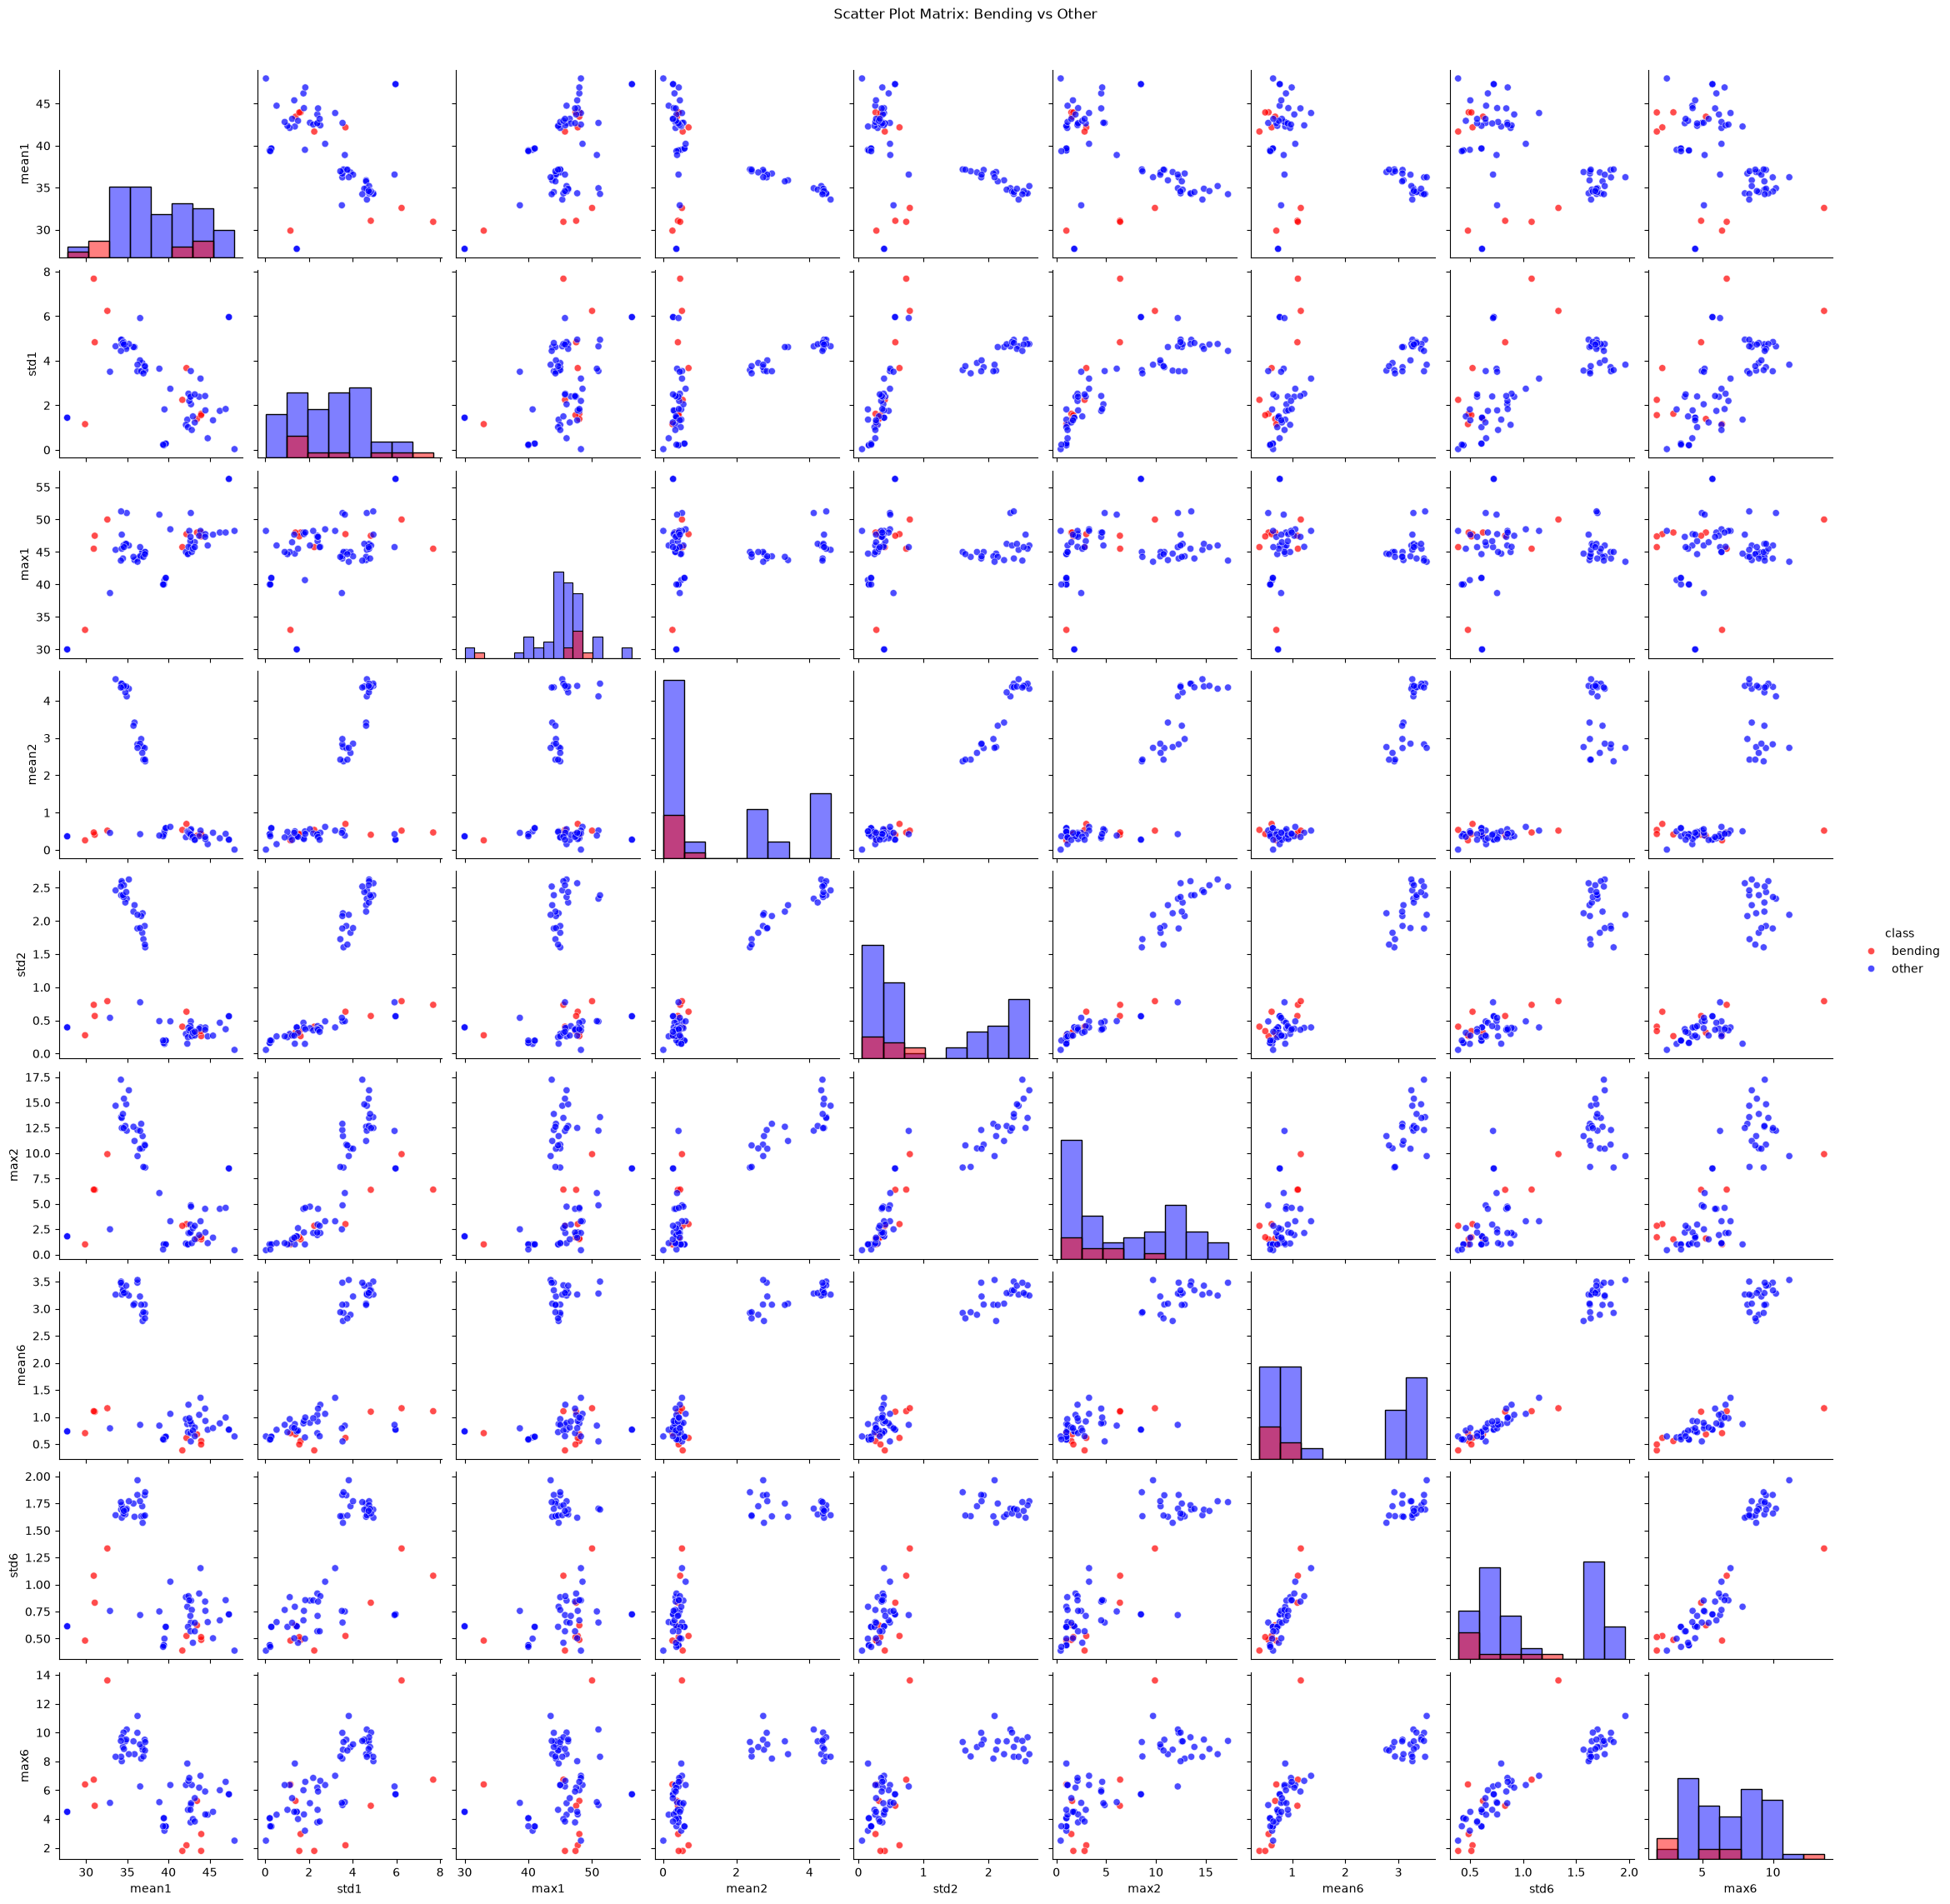

In [9]:
PLOT_FEATURES = [
    "mean1", "std1", "max1",
    "mean2", "std2", "max2",
    "mean6", "std6", "max6"
]

sns.pairplot(
    data=train_feature_df,
    vars=PLOT_FEATURES,
    hue="class",
    palette={
        "bending": "red",
        "other": "blue"
    },
    diag_kind="hist",
    plot_kws={
        "alpha": 0.7,
        "s": 35
    }
)

plt.suptitle(
    "Scatter Plot Matrix: Bending vs Other",
    y=1.02
)

plt.show()

### 2(a)i. Scatter Plot Matrix

The scatter plot matrix shows that the bending and other
activities are partially separable using the selected
time-domain features. However, some overlap remains between
the two classes.

In [11]:
def extract_two_part_features(file_path):
    df = read_sensor_csv(file_path)
    features = {}

    for series_num in SELECTED_SERIES:
        column_name = COLUMN_NAMES[series_num]
        values = df[column_name].to_numpy()

        two_parts = np.array_split(values, 2)

        for part_num, part in enumerate(
            two_parts, start=1
        ):
            prefix = (
                f"series{series_num}_part{part_num}"
            )

            features[f"{prefix}_mean"] = np.mean(part)
            features[f"{prefix}_std"] = np.std(
                part, ddof=1
            )
            features[f"{prefix}_max"] = np.max(part)

    activity = file_path.parent.name

    features["activity"] = activity
    features["class"] = (
        "bending"
        if activity in ["bending1", "bending2"]
        else "other"
    )

    return features

In [12]:
two_part_rows = []

for file_path in train_files:
    one_row = extract_two_part_features(file_path)
    two_part_rows.append(one_row)

two_part_feature_df = pd.DataFrame(two_part_rows)

print(
    "Two-part feature table shape:",
    two_part_feature_df.shape
)

print("\nClass counts:")
print(
    two_part_feature_df["class"].value_counts()
)

two_part_feature_df.head()

Two-part feature table shape: (69, 20)

Class counts:
class
other      60
bending     9
Name: count, dtype: int64


,series1_part1_mean,series1_part1_std,series1_part1_max,series1_part2_mean,series1_part2_std,series1_part2_max,series2_part1_mean,series2_part1_std,series2_part1_max,series2_part2_mean,series2_part2_std,series2_part2_max,series6_part1_mean,series6_part1_std,series6_part1_max,series6_part2_mean,series6_part2_std,series6_part2_max,activity,class
0,43.486208,1.281976,45.00,44.452042,1.771251,48.00,0.378667,0.284434,1.30,0.447583,0.235493,1.50,0.524875,0.486847,2.28,0.585750,0.487918,2.96,bending1,bending
1,44.117042,1.359836,48.00,42.792875,1.058792,46.50,0.250042,0.314099,1.30,0.506125,0.260761,1.58,0.815417,0.718016,5.26,0.543875,0.473445,4.06,bending1,bending
2,43.278875,3.473355,47.75,41.080750,3.537481,46.00,0.673292,0.634285,3.00,0.718792,0.627915,2.86,0.640958,0.554542,1.53,0.586083,0.491873,2.18,bending1,bending
3,41.621208,3.118644,45.75,41.734917,0.595920,43.67,0.623083,0.489595,2.83,0.448875,0.273050,1.12,0.419083,0.411200,1.79,0.347500,0.363144,1.50,bending1,bending
4,44.057167,1.556971,46.50,43.851833,1.557168,47.40,0.381042,0.329540,1.50,0.471458,0.342346,1.70,0.598250,0.526656,1.79,0.388333,0.478528,1.50,bending1,bending


In [13]:
TWO_PART_FEATURES = []

for series_num in SELECTED_SERIES:
    for part_num in [1, 2]:
        for statistic in ["mean", "std", "max"]:
            feature_name = (
                f"series{series_num}_"
                f"part{part_num}_"
                f"{statistic}"
            )
            TWO_PART_FEATURES.append(feature_name)

print("Number of features:",
      len(TWO_PART_FEATURES))
print(TWO_PART_FEATURES)

Number of features: 18
['series1_part1_mean', 'series1_part1_std', 'series1_part1_max', 'series1_part2_mean', 'series1_part2_std', 'series1_part2_max', 'series2_part1_mean', 'series2_part1_std', 'series2_part1_max', 'series2_part2_mean', 'series2_part2_std', 'series2_part2_max', 'series6_part1_mean', 'series6_part1_std', 'series6_part1_max', 'series6_part2_mean', 'series6_part2_std', 'series6_part2_max']


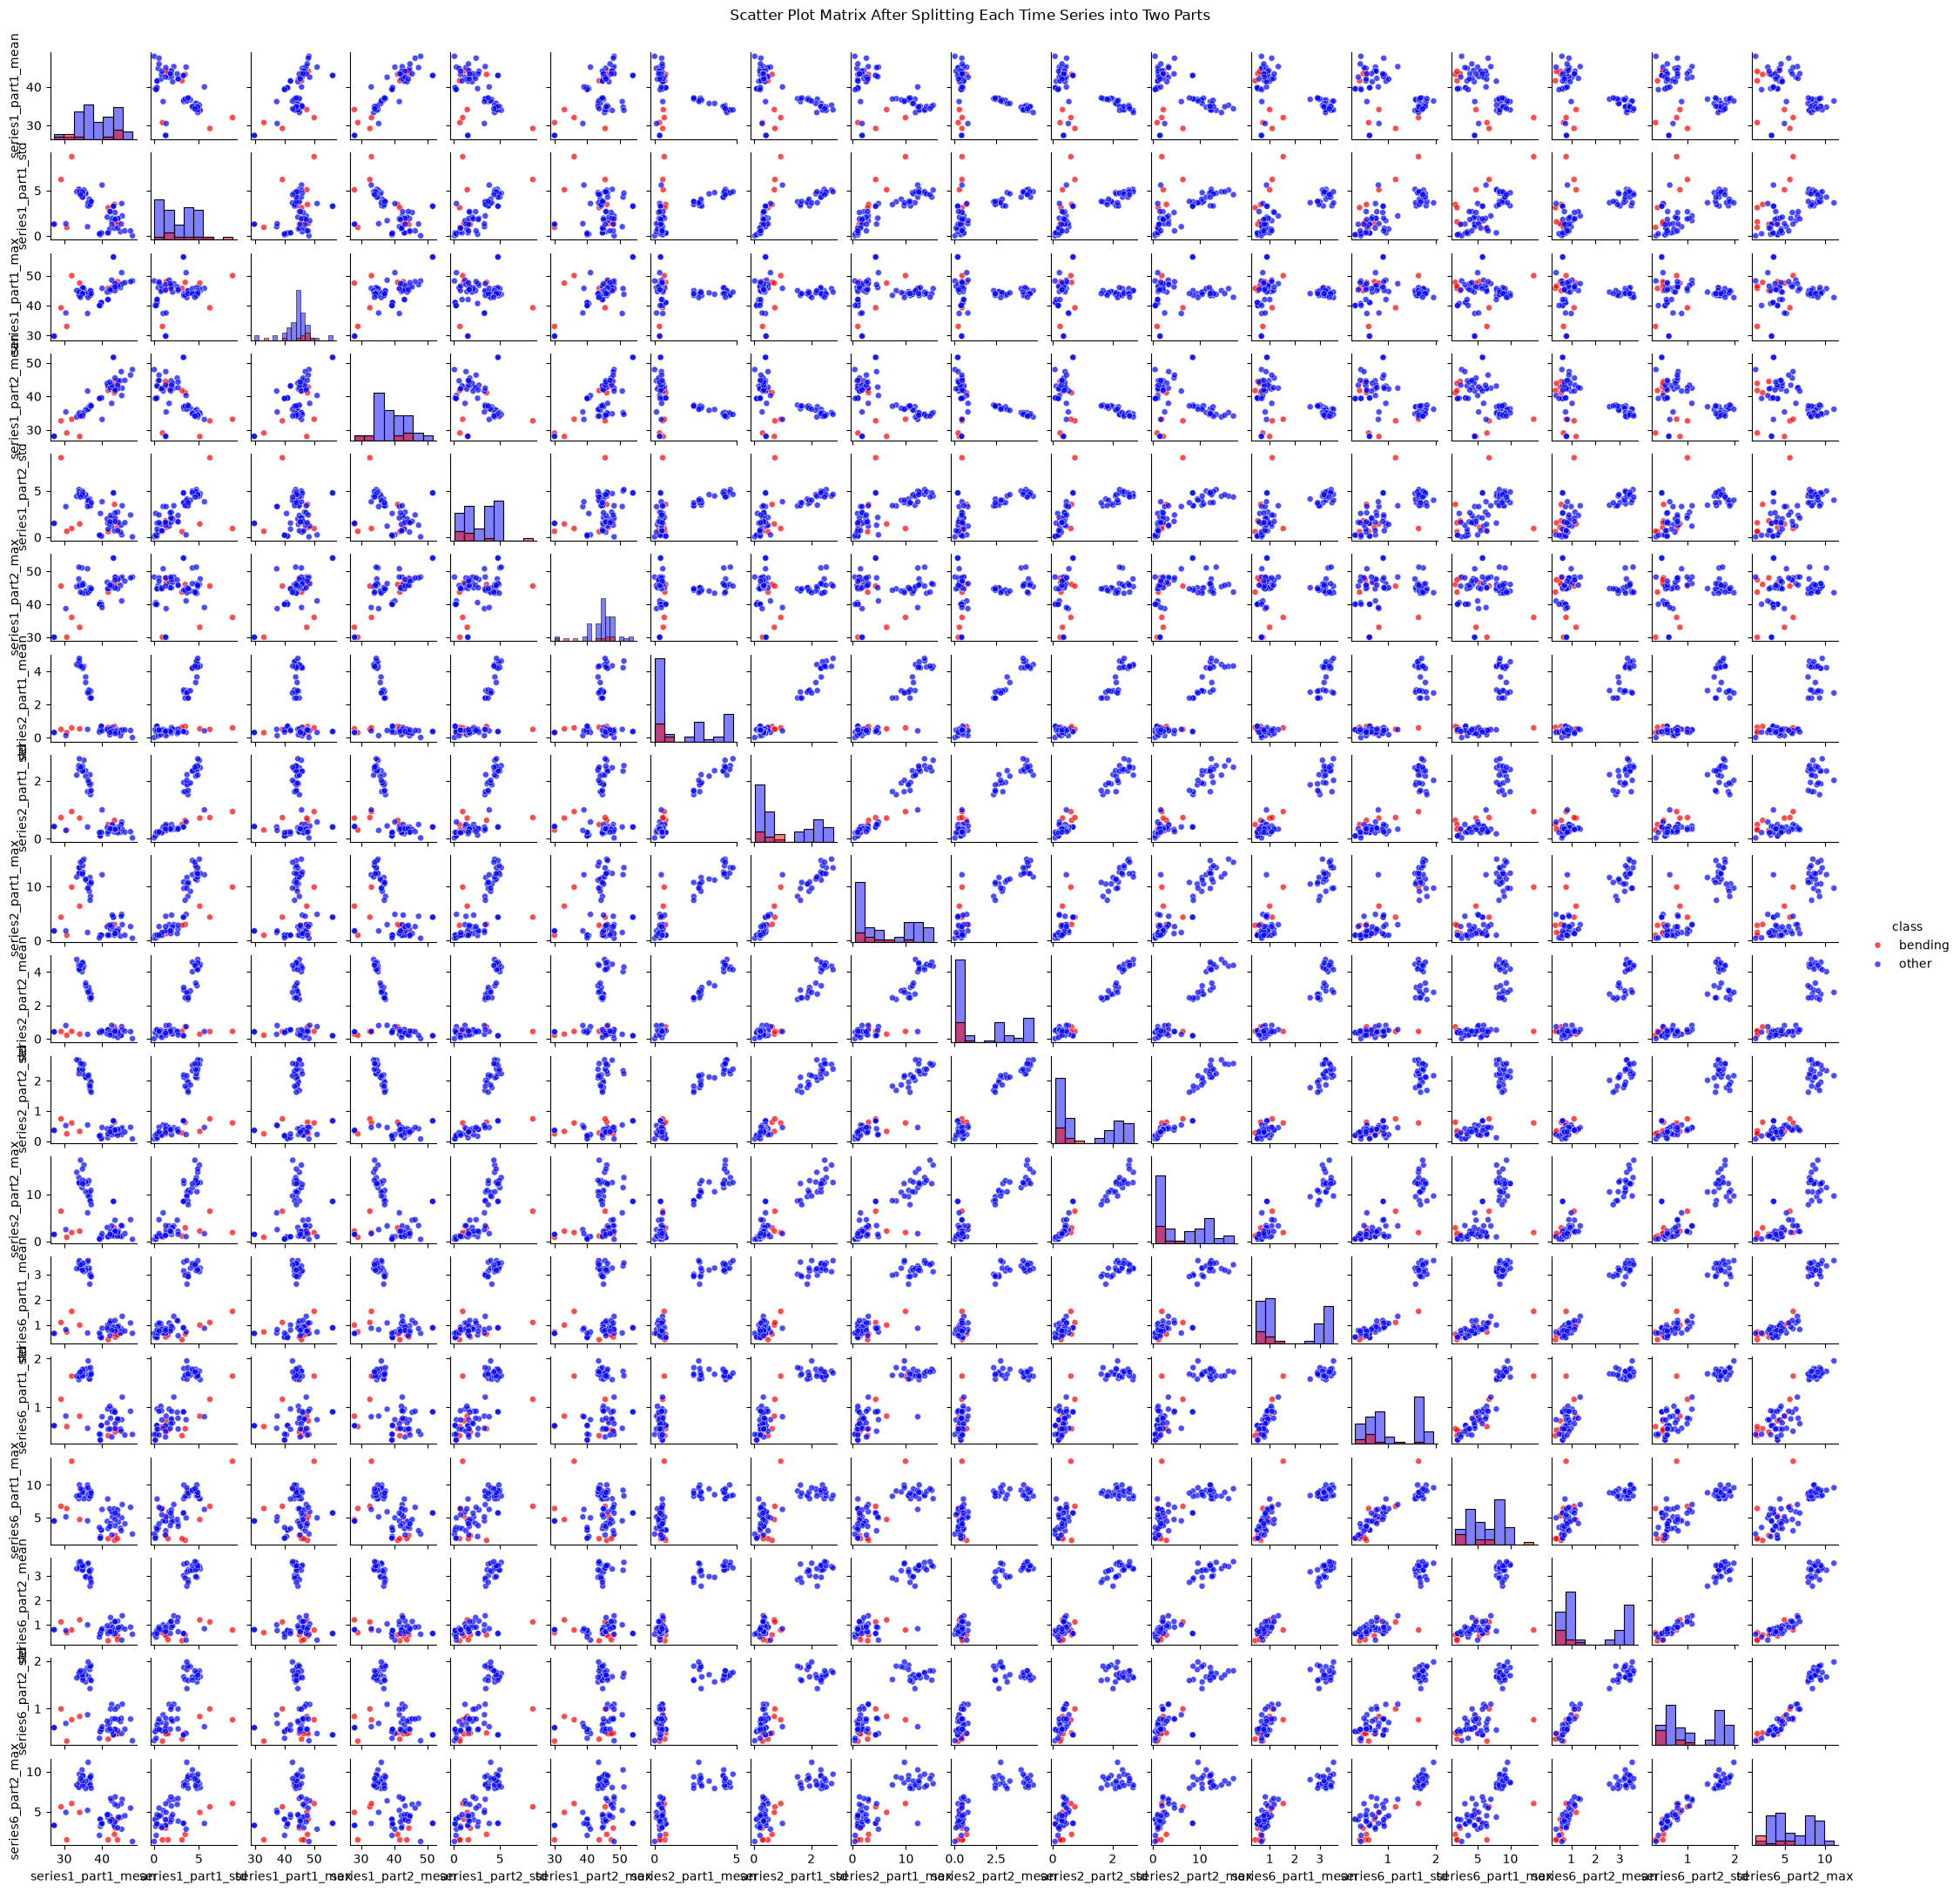

In [15]:
sns.pairplot(
    data=two_part_feature_df,
    vars=TWO_PART_FEATURES,
    hue="class",
    palette={
        "bending": "red",
        "other": "blue"
    },
    diag_kind="hist",
    height=1.2,
    plot_kws={
        "alpha": 0.7,
        "s": 25
    }
)

plt.suptitle(
    "Scatter Plot Matrix After Splitting "
    "Each Time Series into Two Parts",
    y=1.01
)

plt.show()

### 2(a)ii. Scatter Plots After Splitting

After splitting each time series into two parts, more
time-domain features are available. Some feature pairs show
slightly different patterns, but the two classes still
overlap considerably. Therefore, splitting the time series
into two parts does not produce a dramatic improvement in
class separation based on the scatter plots.

### 2(a)iii. Logistic Regression and Cross-Validation

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [19]:
TIME_SERIES_COLUMNS = COLUMN_NAMES[1:]

def extract_features_for_l(file_path, l):
    df = read_sensor_csv(file_path)
    features = {}

    for series_num, column_name in enumerate(
        TIME_SERIES_COLUMNS, start=1
    ):
        values = df[column_name].to_numpy()
        parts = np.array_split(values, l)

        for part_num, part in enumerate(
            parts, start=1
        ):
            prefix = f"s{series_num}_p{part_num}"

            features[f"{prefix}_min"] = np.min(part)
            features[f"{prefix}_max"] = np.max(part)
            features[f"{prefix}_mean"] = np.mean(part)
            features[f"{prefix}_median"] = np.median(part)
            features[f"{prefix}_std"] = np.std(
                part, ddof=1
            )
            features[f"{prefix}_q1"] = np.quantile(
                part, 0.25
            )
            features[f"{prefix}_q3"] = np.quantile(
                part, 0.75
            )

    activity = file_path.parent.name

    features["activity"] = activity
    features["class"] = (
        "bending"
        if activity in ["bending1", "bending2"]
        else "other"
    )
    features["label"] = (
        1
        if activity in ["bending1", "bending2"]
        else 0
    )

    return features

In [20]:
example_l1 = extract_features_for_l(
    train_files[0], l=1
)

example_l2 = extract_features_for_l(
    train_files[0], l=2
)

metadata = ["activity", "class", "label"]

numeric_features_l1 = [
    name for name in example_l1
    if name not in metadata
]

numeric_features_l2 = [
    name for name in example_l2
    if name not in metadata
]

print(
    "Number of numeric features when l=1:",
    len(numeric_features_l1)
)

print(
    "Number of numeric features when l=2:",
    len(numeric_features_l2)
)

print("Activity:", example_l1["activity"])
print("Class:", example_l1["class"])
print("Label:", example_l1["label"])

Number of numeric features when l=1: 42
Number of numeric features when l=2: 84
Activity: bending1
Class: bending
Label: 1


In [22]:
def build_feature_table(file_paths, l):
    rows = []

    for file_path in file_paths:
        one_row = extract_features_for_l(
            file_path, l
        )
        rows.append(one_row)

    table = pd.DataFrame(rows)

    X = table.drop(
        columns=["activity", "class", "label"]
    )
    y = table["label"]

    return X, y, table

In [23]:
X_l1, y_l1, table_l1 = build_feature_table(
    train_files, l=1
)

print("X shape:", X_l1.shape)
print("y shape:", y_l1.shape)

print("\nLabel counts:")
print(y_l1.value_counts())

table_l1.head()

X shape: (69, 42)
y shape: (69,)

Label counts:
label
0    60
1     9
Name: count, dtype: int64


,s1_p1_min,s1_p1_max,s1_p1_mean,s1_p1_median,s1_p1_std,s1_p1_q1,s1_p1_q3,s2_p1_min,s2_p1_max,s2_p1_mean,...,s6_p1_min,s6_p1_max,s6_p1_mean,s6_p1_median,s6_p1_std,s6_p1_q1,s6_p1_q3,activity,class,label
0,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,0.0,1.50,0.413125,...,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83,bending1,bending,1
1,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,0.0,1.58,0.378083,...,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87,bending1,bending,1
2,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00,bending1,bending,1
3,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50,bending1,bending,1
4,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94,bending1,bending,1


In [24]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold_num, (train_index, validation_index) in enumerate(
    cv.split(X_l1, y_l1),
    start=1
):
    y_train_fold = y_l1.iloc[train_index]
    y_validation_fold = y_l1.iloc[validation_index]

    print(f"Fold {fold_num}")
    print(
        "Training counts:",
        y_train_fold.value_counts().to_dict()
    )
    print(
        "Validation counts:",
        y_validation_fold.value_counts().to_dict()
    )
    print()

Fold 1
Training counts: {0: 48, 1: 7}
Validation counts: {0: 12, 1: 2}

Fold 2
Training counts: {0: 48, 1: 7}
Validation counts: {0: 12, 1: 2}

Fold 3
Training counts: {0: 48, 1: 7}
Validation counts: {0: 12, 1: 2}

Fold 4
Training counts: {0: 48, 1: 7}
Validation counts: {0: 12, 1: 2}

Fold 5
Training counts: {0: 48, 1: 8}
Validation counts: {0: 12, 1: 1}



In [25]:
example_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "selector",
        RFE(
            estimator=LogisticRegression(
                solver="liblinear",
                max_iter=5000
            ),
            n_features_to_select=5
        )
    ),
    (
        "logistic",
        LogisticRegression(
            solver="liblinear",
            max_iter=5000
        )
    )
])

example_scores = cross_val_score(
    example_model,
    X_l1,
    y_l1,
    cv=cv,
    scoring="accuracy"
)

print("Accuracy for each fold:", example_scores)
print("Mean CV accuracy:", example_scores.mean())
print("Mean CV error:", 1 - example_scores.mean())

Accuracy for each fold: [1.         1.         0.92857143 1.         1.        ]
Mean CV accuracy: 0.9857142857142858
Mean CV error: 0.014285714285714235


In [26]:
def evaluate_l_p(l, p):
    X, y, table = build_feature_table(
        train_files, l
    )

    model = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "selector",
            RFE(
                estimator=LogisticRegression(
                    solver="liblinear",
                    max_iter=5000
                ),
                n_features_to_select=p,
                step=0.1
            )
        ),
        (
            "logistic",
            LogisticRegression(
                solver="liblinear",
                max_iter=5000
            )
        )
    ])

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    mean_accuracy = scores.mean()
    mean_error = 1 - mean_accuracy

    return mean_accuracy, mean_error

In [27]:
accuracy, error = evaluate_l_p(
    l=1,
    p=5
)

print("Mean accuracy:", accuracy)
print("Mean error:", error)

Mean accuracy: 0.9857142857142858
Mean error: 0.014285714285714235


In [28]:
search_results = []

for l in range(1, 21):
    X_l, y_l, table_l = build_feature_table(
        train_files, l
    )

    for p in range(1, 21):
        model = Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "selector",
                RFE(
                    estimator=LogisticRegression(
                        solver="liblinear",
                        max_iter=5000
                    ),
                    n_features_to_select=p,
                    step=0.1
                )
            ),
            (
                "logistic",
                LogisticRegression(
                    solver="liblinear",
                    max_iter=5000
                )
            )
        ])

        scores = cross_val_score(
            model,
            X_l,
            y_l,
            cv=cv,
            scoring="accuracy"
        )

        search_results.append({
            "l": l,
            "p": p,
            "mean_accuracy": scores.mean(),
            "mean_error": 1 - scores.mean()
        })

    print(f"Finished l={l}")

Finished l=1
Finished l=2
Finished l=3
Finished l=4
Finished l=5
Finished l=6
Finished l=7
Finished l=8
Finished l=9
Finished l=10
Finished l=11
Finished l=12
Finished l=13
Finished l=14
Finished l=15
Finished l=16
Finished l=17
Finished l=18
Finished l=19
Finished l=20


In [29]:
results_df = pd.DataFrame(search_results)

sorted_results = results_df.sort_values(
    by=["mean_error", "l", "p"]
).reset_index(drop=True)

sorted_results.head(10)

,l,p,mean_accuracy,mean_error
0,1,5,0.985714,0.014286
1,1,9,0.985714,0.014286
2,3,1,0.985714,0.014286
3,10,12,0.985714,0.014286
4,10,13,0.985714,0.014286
5,10,14,0.985714,0.014286
6,10,15,0.985714,0.014286
7,10,16,0.985714,0.014286
8,10,17,0.985714,0.014286
9,10,18,0.985714,0.014286


In [30]:
best_result = sorted_results.iloc[0]

best_l = int(best_result["l"])
best_p = int(best_result["p"])
best_accuracy = best_result["mean_accuracy"]
best_error = best_result["mean_error"]

print("Best l:", best_l)
print("Best p:", best_p)
print("Best CV accuracy:", best_accuracy)
print("Best CV error:", best_error)

Best l: 1
Best p: 5
Best CV accuracy: 0.9857142857142858
Best CV error: 0.014285714285714235


### 2(a)iii. Selection of l and p

Recursive Feature Elimination (RFE) with logistic regression was
used to select the features. Stratified 5-fold cross-validation was
used to compare values of l from 1 to 20 and values of p from 1 to 20.

The best selected combination was l = 1 and p = 5. Its mean
cross-validation accuracy was approximately 0.9857, corresponding
to a mean cross-validation error of approximately 0.0143. Several
combinations produced the same accuracy, so the combination with the
smaller value of l and fewer features was preferred.

The correct cross-validation procedure performs feature scaling and
RFE separately within each training fold, and then evaluates the
result on the corresponding validation fold. This was accomplished
using a pipeline.

The incorrect procedure would scale the data or select features using
the entire training data set before cross-validation. In that case,
information from the validation fold would influence feature
selection, causing data leakage and an overly optimistic estimate of
model performance.

### 2(a)iv. Confusion Matrix, ROC, AUC, and Logistic Regression Coefficients

In [32]:
# Build the training dataset using the best l
X_train, y_train, train_table = build_feature_table(
    train_files, best_l
)

# Build the final logistic regression pipeline
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("selector", RFE(
        estimator=LogisticRegression(
            solver="liblinear",
            max_iter=5000
        ),
        n_features_to_select=best_p,
        step=0.1
    )),
    ("logistic", LogisticRegression(
        solver="liblinear",
        max_iter=5000
    ))
])

# Fit the model on the full training set
final_model.fit(X_train, y_train)

print("Training data shape:", X_train.shape)
print("Best l:", best_l)
print("Best p:", best_p)
print("Final model trained successfully!")

Training data shape: (69, 42)
Best l: 1
Best p: 5
Final model trained successfully!


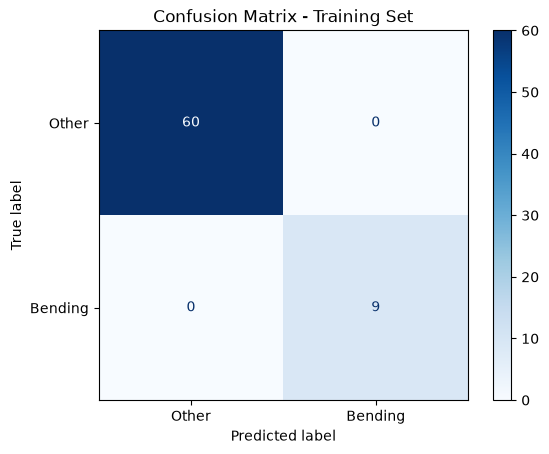

Training Accuracy: 1.0


In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict labels on the training set
y_train_pred = final_model.predict(X_train)

# Calculate confusion matrix
cm_train = confusion_matrix(y_train, y_train_pred, labels=[0, 1])

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_train,
    display_labels=["Other", "Bending"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Training Set")
plt.show()

# Calculate training accuracy
train_accuracy = final_model.score(X_train, y_train)

print("Training Accuracy:", train_accuracy)

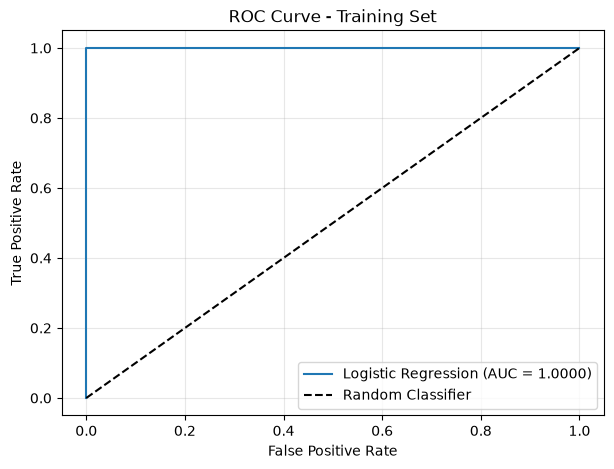

Training AUC: 1.0


In [34]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Predict probabilities for the positive class (Bending)
y_train_prob = final_model.predict_proba(X_train)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_train, y_train_prob)

# Calculate AUC
train_auc = roc_auc_score(y_train, y_train_prob)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {train_auc:.4f})"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Training Set")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print("Training AUC:", train_auc)

In [35]:
import pandas as pd
import numpy as np

# Get selected features from RFE
selected_mask = final_model.named_steps["selector"].support_

selected_features = X_train.columns[selected_mask]

# Get logistic regression coefficients
coefficients = final_model.named_steps["logistic"].coef_[0]

intercept = final_model.named_steps["logistic"].intercept_[0]

# Create a table
coef_table = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient (Beta)": coefficients
})

print("Intercept (Beta 0):", intercept)

display(coef_table)

Intercept (Beta 0): -2.395469072086097


,Feature,Coefficient (Beta)
0,s1_p1_q3,-0.644329
1,s5_p1_min,0.793337
2,s5_p1_max,1.189757
3,s5_p1_mean,0.607836
4,s6_p1_q1,-0.951891


In [36]:
import statsmodels.api as sm
import pandas as pd
import numpy as np
import warnings

# Get the standardized features selected by RFE
X_scaled = final_model.named_steps["scaler"].transform(X_train)

X_selected = final_model.named_steps["selector"].transform(X_scaled)

# Add intercept
X_selected_sm = sm.add_constant(X_selected, has_constant="add")

# Fit logistic regression for statistical inference
with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always")

    try:
        logit_model = sm.Logit(y_train, X_selected_sm)
        logit_result = logit_model.fit(disp=False, maxiter=100)

        pvalue_table = pd.DataFrame({
            "Feature": ["Intercept"] + list(selected_features),
            "Coefficient": logit_result.params,
            "P-value": logit_result.pvalues
        })

        display(pvalue_table)

        if caught_warnings:
            print("Warnings:")
            for warning in caught_warnings:
                print(str(warning.message))

    except Exception as e:
        print("Standard logistic regression could not be estimated.")
        print("Reason:", e)

,Feature,Coefficient,P-value
const,Intercept,-52.447042,0.999762
x1,s1_p1_q3,-26.487267,0.999810
x2,s5_p1_min,27.673152,0.999943
x3,s5_p1_max,23.968065,0.999827
x4,s5_p1_mean,16.445093,0.999966
x5,s6_p1_q1,-14.416210,0.999932


Warnings:
Perfect separation or prediction detected, parameter may not be identified
Perfect separation or prediction detected, parameter may not be identified
Perfect separation or prediction detected, parameter may not be identified
Perfect separation or prediction detected, parameter may not be identified
Perfect separation or prediction detected, parameter may not be identified
Perfect separation or prediction detected, parameter may not be identified
Perfect separation or prediction detected, parameter may not be identified
Perfect separation or prediction detected, parameter may not be identified
Perfect separation or prediction detected, parameter may not be identified
Perfect separation or prediction detected, parameter may not be identified
Perfect separation or prediction detected, parameter may not be identified
Perfect separation or prediction detected, parameter may not be identified
Perfect separation or prediction detected, parameter may not be identified
Perfect separat

#### Logistic Regression Parameter Estimation

The logistic regression model achieved 100% training accuracy
and an AUC of 1.0.

When fitting an unregularized logistic regression model using
statsmodels, perfect separation warnings were detected, and
the maximum likelihood optimization failed to converge.

This suggests that the classes are completely separated in
the selected feature space, making the maximum likelihood
estimates of the regression coefficients unstable.

Therefore, conventional Wald p-values cannot be reliably
interpreted for this model.

The coefficients reported above were obtained from the
regularized scikit-learn logistic regression model.

Although numerical p-values were produced, they are not
reliable because the unregularized logistic regression model
failed to converge under perfect separation. Therefore,
no statistical significance conclusions are drawn from
these p-values.

### 2(a)v. Test Set Evaluation

In [37]:
from sklearn.metrics import accuracy_score, confusion_matrix

# Extract test features using the best l
X_test, y_test, test_table = build_feature_table(
    test_files, best_l
)

# Predict test labels
y_test_pred = final_model.predict(X_test)

# Calculate test accuracy
test_accuracy = accuracy_score(y_test, y_test_pred)
test_error = 1 - test_accuracy

# Compare with cross-validation accuracy
print("Test data shape:", X_test.shape)
print("Test Accuracy:", test_accuracy)
print("Test Error:", test_error)
print("CV Accuracy:", best_accuracy)
print("CV Error:", best_error)

# Display test confusion matrix
print("\nTest Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=[0, 1]))

Test data shape: (19, 42)
Test Accuracy: 1.0
Test Error: 0.0
CV Accuracy: 0.9857142857142858
CV Error: 0.014285714285714235

Test Confusion Matrix:
[[15  0]
 [ 0  4]]


#### Results and Discussion

The best parameters selected by 5-fold cross-validation were
l = 1 and p = 5.

The final logistic regression model was evaluated on the
independent test set containing 19 instances.

The test accuracy was 1.0000 (100%), corresponding to a
test error of 0.0000 (0%).

The test confusion matrix was:

| Actual / Predicted | Other | Bending |
|---|---:|---:|
| Other | 15 | 0 |
| Bending | 0 | 4 |

All 15 non-bending instances and all 4 bending instances
were correctly classified.

The test accuracy of 100% was slightly higher than the
cross-validation accuracy of approximately 98.57%.

This difference may be due to the relatively small test
set and the fact that the final model was trained using
the entire training dataset.

Although the model achieved perfect classification on
the test set, this does not guarantee perfect performance
on unseen data.

### 2(a)vi. Logistic Regression Instability

Yes, the two classes appear to be completely separated in the selected feature space.

The logistic regression model achieved 100% training accuracy and an AUC of 1.0, indicating perfect discrimination between bending and non-bending activities on the training set.

When fitting an unregularized logistic regression model using statsmodels, perfect separation warnings were detected, and the maximum likelihood optimization failed to converge.

Under complete separation, the logistic regression coefficients may increase without bound, making the maximum likelihood estimates unstable and conventional Wald p-values unreliable.

Regularization can help obtain finite coefficient estimates, although it does not eliminate the underlying separation in the data.

Therefore, the results indicate that class separation causes instability in estimating the unregularized logistic regression parameters.

### 2(a)vii. Class Imbalance and Case-Control Sampling

In [38]:
from sklearn.utils import resample
import pandas as pd

# Combine training features and labels
train_data = X_train.copy()
train_data["label"] = y_train.to_numpy()

# Separate the two classes
other_data = train_data[train_data["label"] == 0]
bending_data = train_data[train_data["label"] == 1]

# Randomly sample the majority class
other_sampled = resample(
    other_data,
    replace=False,
    n_samples=len(bending_data),
    random_state=42
)

# Combine the sampled data
balanced_data = pd.concat(
    [other_sampled, bending_data],
    axis=0
).sample(frac=1, random_state=42)

# Separate features and labels
X_balanced = balanced_data.drop(columns=["label"])
y_balanced = balanced_data["label"]

print("Original class distribution:")
print(y_train.value_counts())

print("\nBalanced class distribution:")
print(y_balanced.value_counts())

Original class distribution:
label
0    60
1     9
Name: count, dtype: int64

Balanced class distribution:
label
0    9
1    9
Name: count, dtype: int64


In [39]:
from sklearn.base import clone
import numpy as np

# Train a logistic regression model on balanced data
balanced_model = clone(final_model)
balanced_model.fit(X_balanced, y_balanced)

# Calculate class proportions
pi_original = y_train.mean()
pi_sampled = y_balanced.mean()

# Calculate intercept correction
intercept_correction = np.log(
    (pi_original / (1 - pi_original)) /
    (pi_sampled / (1 - pi_sampled))
)

# Adjust the intercept
original_intercept = balanced_model.named_steps["logistic"].intercept_[0]

adjusted_intercept = original_intercept + intercept_correction

balanced_model.named_steps["logistic"].intercept_[0] = adjusted_intercept

print("Original Bending proportion:", pi_original)
print("Sampled Bending proportion:", pi_sampled)
print("Intercept correction:", intercept_correction)
print("Intercept before adjustment:", original_intercept)
print("Intercept after adjustment:", adjusted_intercept)
print("Case-control logistic regression model trained successfully!")

Original Bending proportion: 0.13043478260869565
Sampled Bending proportion: 0.5
Intercept correction: -1.8971199848858813
Intercept before adjustment: 0.15082485635513562
Intercept after adjustment: -1.7462951285307458
Case-control logistic regression model trained successfully!


Case-Control Training Accuracy: 0.927536231884058
Case-Control Confusion Matrix:
[[60  0]
 [ 5  4]]


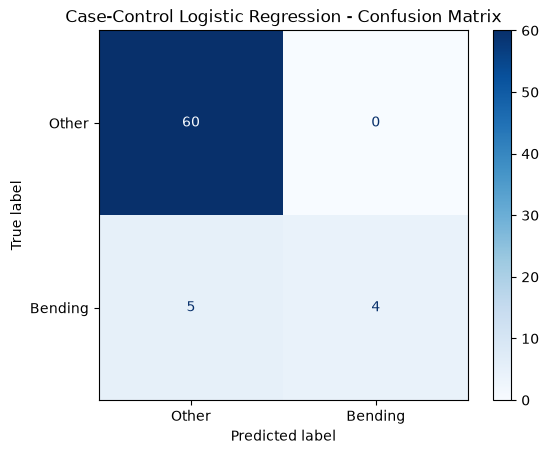

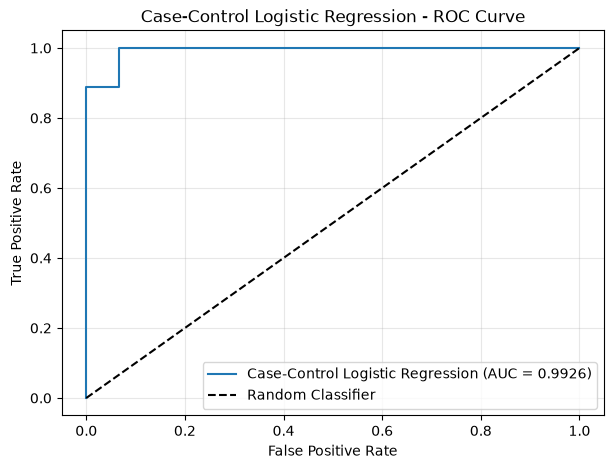

Case-Control AUC: 0.9925925925925926


In [40]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    accuracy_score
)
import matplotlib.pyplot as plt

# Predict on the original training set
y_cc_pred = balanced_model.predict(X_train)
y_cc_prob = balanced_model.predict_proba(X_train)[:, 1]

# Calculate accuracy
cc_accuracy = accuracy_score(y_train, y_cc_pred)

# Calculate confusion matrix
cc_cm = confusion_matrix(y_train, y_cc_pred, labels=[0, 1])

print("Case-Control Training Accuracy:", cc_accuracy)
print("Case-Control Confusion Matrix:")
print(cc_cm)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cc_cm,
    display_labels=["Other", "Bending"]
)

disp.plot(cmap="Blues")
plt.title("Case-Control Logistic Regression - Confusion Matrix")
plt.show()

# Calculate ROC and AUC
cc_fpr, cc_tpr, cc_thresholds = roc_curve(y_train, y_cc_prob)
cc_auc = roc_auc_score(y_train, y_cc_prob)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    cc_fpr,
    cc_tpr,
    label=f"Case-Control Logistic Regression (AUC = {cc_auc:.4f})"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Case-Control Logistic Regression - ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print("Case-Control AUC:", cc_auc)

#### Results and Discussion

The original training dataset contained 60 non-bending instances and 9 bending instances, indicating a significant class imbalance.

Case-control sampling was performed by randomly selecting 9 non-bending instances while retaining all 9 bending instances. This produced a balanced training dataset containing 18 instances.

A logistic regression model was trained on the balanced dataset. The intercept was adjusted to account for the original class proportions.

The intercept correction was approximately -1.8971, and the adjusted intercept was approximately -1.7463.

The adjusted model was evaluated on the original training dataset containing 69 instances.

The model achieved a training accuracy of 0.9275 (92.75%) and an AUC of 0.9926.

The confusion matrix was:

| Actual / Predicted | Other | Bending |
|---|---:|---:|
| Other | 60 | 0 |
| Bending | 5 | 4 |

All 60 non-bending instances were correctly classified. However, only 4 out of 9 bending instances were correctly identified, while 5 bending instances were incorrectly classified as non-bending.

Compared with the original logistic regression model, which achieved 100% training accuracy and an AUC of 1.0, the case-control model showed slightly lower performance.

Although the case-control model maintained strong discrimination between the two classes, the intercept adjustment reduced the predicted probability of bending, resulting in more false negatives at the default classification threshold.

Therefore, case-control sampling did not improve the classification performance in this experiment.

### 2(b)i. L1-Penalized Logistic Regression

In [51]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Define cross-validation
cv_l1 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 2. Define candidate C values
C_values = np.logspace(-3, 3, 10)

# 3. Create the L1 logistic regression model
l1_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        l1_ratio=1.0,
        solver="liblinear",
        max_iter=5000,
        random_state=42
    ))
])

# 4. Search for the best l and C
l1_results = []

for l in range(1, 21):

    X_l, y_l, _ = build_feature_table(train_files, l)

    grid_l1 = GridSearchCV(
        estimator=l1_pipeline,
        param_grid={"logistic__C": C_values},
        cv=cv_l1,
        scoring="accuracy",
        n_jobs=-1
    )

    grid_l1.fit(X_l, y_l)

    l1_results.append({
        "l": l,
        "best_C": grid_l1.best_params_["logistic__C"],
        "CV_accuracy": grid_l1.best_score_,
        "CV_error": 1 - grid_l1.best_score_
    })

    print(
        f"l = {l}, "
        f"Best C = {grid_l1.best_params_['logistic__C']:.4f}, "
        f"CV Accuracy = {grid_l1.best_score_:.4f}"
    )

# 5. Create results table
l1_results_df = pd.DataFrame(l1_results)

l1_results_df = l1_results_df.sort_values(
    by=["CV_accuracy", "l"],
    ascending=[False, True]
).reset_index(drop=True)

display(l1_results_df)

# 6. Select best parameters
best_l_l1 = int(l1_results_df.iloc[0]["l"])
best_C_l1 = float(l1_results_df.iloc[0]["best_C"])
best_accuracy_l1 = float(l1_results_df.iloc[0]["CV_accuracy"])

print("\nBest l:", best_l_l1)
print("Best C:", best_C_l1)
print("Best CV Accuracy:", best_accuracy_l1)
print("Best CV Error:", 1 - best_accuracy_l1)

l = 1, Best C = 1000.0000, CV Accuracy = 0.9857
l = 2, Best C = 10.0000, CV Accuracy = 0.9714
l = 3, Best C = 0.4642, CV Accuracy = 0.9714
l = 4, Best C = 0.4642, CV Accuracy = 0.9714
l = 5, Best C = 0.4642, CV Accuracy = 0.9429
l = 6, Best C = 10.0000, CV Accuracy = 0.9429
l = 7, Best C = 0.4642, CV Accuracy = 0.9286
l = 8, Best C = 46.4159, CV Accuracy = 0.9286
l = 9, Best C = 10.0000, CV Accuracy = 0.9714
l = 10, Best C = 215.4435, CV Accuracy = 0.9714
l = 11, Best C = 2.1544, CV Accuracy = 0.9857
l = 12, Best C = 2.1544, CV Accuracy = 0.9857
l = 13, Best C = 2.1544, CV Accuracy = 0.9714
l = 14, Best C = 0.4642, CV Accuracy = 0.9429
l = 15, Best C = 46.4159, CV Accuracy = 0.9286
l = 16, Best C = 46.4159, CV Accuracy = 0.9571
l = 17, Best C = 10.0000, CV Accuracy = 0.9571
l = 18, Best C = 2.1544, CV Accuracy = 0.9857
l = 19, Best C = 0.4642, CV Accuracy = 0.9714
l = 20, Best C = 10.0000, CV Accuracy = 0.9857


,l,best_C,CV_accuracy,CV_error
0,1,1000.000000,0.985714,0.014286
1,11,2.154435,0.985714,0.014286
2,12,2.154435,0.985714,0.014286
3,18,2.154435,0.985714,0.014286
4,20,10.000000,0.985714,0.014286
5,2,10.000000,0.971429,0.028571
6,3,0.464159,0.971429,0.028571
7,4,0.464159,0.971429,0.028571
8,9,10.000000,0.971429,0.028571
9,10,215.443469,0.971429,0.028571



Best l: 1
Best C: 1000.0
Best CV Accuracy: 0.9857142857142858
Best CV Error: 0.014285714285714235


In [52]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score

X_train_l1, y_train_l1, _ = build_feature_table(
    train_files, best_l_l1
)

X_test_l1, y_test_l1, _ = build_feature_table(
    test_files, best_l_l1
)

final_l1_model = clone(l1_pipeline)
final_l1_model.set_params(logistic__C=best_C_l1)

final_l1_model.fit(X_train_l1, y_train_l1)

y_test_pred_l1 = final_l1_model.predict(X_test_l1)

l1_test_accuracy = accuracy_score(y_test_l1, y_test_pred_l1)

print("Best l:", best_l_l1)
print("Best C:", best_C_l1)
print("L1 CV Accuracy:", best_accuracy_l1)
print("L1 Test Accuracy:", l1_test_accuracy)
print("L1 Test Error:", 1 - l1_test_accuracy)

Best l: 1
Best C: 1000.0
L1 CV Accuracy: 0.9857142857142858
L1 Test Accuracy: 1.0
L1 Test Error: 0.0


#### Results and Discussion

L1-penalized logistic regression was used to classify bending and non-bending activities.

Each time series was divided into l segments, with l ranging from 1 to 20. The regularization parameter C was selected from 10 candidate values between 0.001 and 1000.

Stratified 5-fold cross-validation was used to select the best combination of l and C. Feature standardization was performed within each training fold using a pipeline to avoid data leakage.

The selected parameters were l = 1 and C = 1000.

The mean cross-validation accuracy was 0.9857 (98.57%), corresponding to a cross-validation error of 0.0143 (1.43%).

The final L1-penalized logistic regression model was trained using the full training set and evaluated on the independent test set.

The test accuracy was 1.0000 (100%), corresponding to a test error of 0.0000 (0%).

Several parameter combinations achieved the same cross-validation accuracy. The reported combination was selected according to the sorting rule used in the parameter search.

Overall, the L1-penalized logistic regression model achieved high classification accuracy on this dataset.

### 2(b)ii. Comparison of L1-Penalized Logistic Regression and Feature Selection

The L1-penalized logistic regression model was compared with the logistic regression model using Recursive Feature Elimination (RFE) from Question 2(a)iii.

Both methods achieved a mean cross-validation accuracy of approximately 98.57% and a test accuracy of 100%. Therefore, neither method demonstrated better predictive performance in this experiment.

The RFE-based method selected five features with l = 1, while the L1-penalized method selected l = 1 and C = 1000.

L1 regularization is generally easier to implement because it performs feature selection during model fitting by shrinking some coefficients to zero. In contrast, RFE requires a separate feature elimination procedure.

Although the assignment also mentions p-value-based feature selection, RFE was used as the alternative method in Question 2(a)iii. The unregularized logistic regression model also encountered perfect separation, making conventional Wald p-values unreliable.

Overall, both methods achieved the same classification accuracy, while L1-penalized logistic regression was easier to implement.

### 2(c)i. Multiclass Classification Using L1-Penalized Logistic Regression

In [53]:
print("Training files:")
print(train_files[:5])

print("\nTest files:")
print(test_files[:5])

print("\nTraining file count:", len(train_files))
print("Test file count:", len(test_files))

Training files:
[PosixPath('../data/AReM/bending1/dataset7.csv'), PosixPath('../data/AReM/bending1/dataset6.csv'), PosixPath('../data/AReM/bending1/dataset4.csv'), PosixPath('../data/AReM/bending1/dataset5.csv'), PosixPath('../data/AReM/bending1/dataset3.csv')]

Test files:
[PosixPath('../data/AReM/bending1/dataset1.csv'), PosixPath('../data/AReM/bending1/dataset2.csv'), PosixPath('../data/AReM/bending2/dataset1.csv'), PosixPath('../data/AReM/bending2/dataset2.csv'), PosixPath('../data/AReM/cycling/dataset1.csv')]

Training file count: 69
Test file count: 19


In [54]:
# Activity labels
activity_names = [
    "bending1", "bending2", "cycling",
    "lying", "sitting", "standing", "walking"
]

def build_multiclass_features(file_list, l):
    rows = []
    labels = []

    for file_path in file_list:
        features = extract_features_for_l(file_path, l)
        rows.append(features)

        activity = file_path.parent.name
        labels.append(activity)

    X = pd.DataFrame(rows).fillna(0)
    y = pd.Series(labels, name="activity")

    return X, y


X_train_multi, y_train_multi = build_multiclass_features(
    train_files, 1
)

X_test_multi, y_test_multi = build_multiclass_features(
    test_files, 1
)

print("Training shape:", X_train_multi.shape)
print("Test shape:", X_test_multi.shape)

print("\nTraining class distribution:")
print(y_train_multi.value_counts())

print("\nTest class distribution:")
print(y_test_multi.value_counts())

Training shape: (69, 45)
Test shape: (19, 45)

Training class distribution:
activity
cycling     12
lying       12
sitting     12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64

Test class distribution:
activity
cycling     3
lying       3
sitting     3
standing    3
walking     3
bending1    2
bending2    2
Name: count, dtype: int64


In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
import numpy as np

multi_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        solver="saga",
        l1_ratio=1.0,
        max_iter=10000,
        random_state=42
    ))
])

cv_multi = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

C_values_multi = np.logspace(-3, 3, 10)

print("Multiclass L1 Logistic Regression pipeline created!")
print("Number of classes:", y_train_multi.nunique())
print("CV folds:", cv_multi.get_n_splits())
print("C values:", C_values_multi)

Multiclass L1 Logistic Regression pipeline created!
Number of classes: 7
CV folds: 4
C values: [1.00000000e-03 4.64158883e-03 2.15443469e-02 1.00000000e-01
 4.64158883e-01 2.15443469e+00 1.00000000e+01 4.64158883e+01
 2.15443469e+02 1.00000000e+03]


In [58]:
from sklearn.impute import SimpleImputer

cv_multi = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

C_values_multi = np.logspace(-3, 3, 10)

multi_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        solver="saga",
        l1_ratio=1.0,
        max_iter=10000,
        tol=1e-3,
        random_state=42
    ))
])

multi_results = []

for l in range(1, 21):

    X_l, y_l = build_multiclass_features(train_files, l)

    X_l = X_l.apply(pd.to_numeric, errors="coerce")
    X_l = X_l.replace([np.inf, -np.inf], np.nan)

    grid_multi = GridSearchCV(
        estimator=multi_pipeline,
        param_grid={"logistic__C": C_values_multi},
        cv=cv_multi,
        scoring="accuracy",
        n_jobs=-1,
        error_score="raise"
    )

    try:
        grid_multi.fit(X_l, y_l)

    except Exception as e:
        print(f"Error at l = {l}: {type(e).__name__}: {e}")
        raise

    multi_results.append({
        "l": l,
        "best_C": grid_multi.best_params_["logistic__C"],
        "CV_accuracy": grid_multi.best_score_,
        "CV_error": 1 - grid_multi.best_score_
    })

    print(
        f"l = {l}, "
        f"C = {grid_multi.best_params_['logistic__C']:.4f}, "
        f"Accuracy = {grid_multi.best_score_:.4f}",
        flush=True
    )

multi_results_df = pd.DataFrame(multi_results)

multi_results_df = multi_results_df.sort_values(
    ["CV_accuracy", "l"],
    ascending=[False, True]
).reset_index(drop=True)

display(multi_results_df)

best_l_multi = int(multi_results_df.iloc[0]["l"])
best_C_multi = float(multi_results_df.iloc[0]["best_C"])
best_cv_multi = float(multi_results_df.iloc[0]["CV_accuracy"])

print("\nBest l:", best_l_multi)
print("Best C:", best_C_multi)
print("Best CV Accuracy:", best_cv_multi)
print("Best CV Error:", 1 - best_cv_multi)

l = 1, C = 2.1544, Accuracy = 0.9281
l = 2, C = 0.4642, Accuracy = 0.9289
l = 3, C = 10.0000, Accuracy = 0.8693
l = 4, C = 46.4159, Accuracy = 0.9126
l = 5, C = 10.0000, Accuracy = 0.8832
l = 6, C = 2.1544, Accuracy = 0.8538
l = 7, C = 215.4435, Accuracy = 0.8407
l = 8, C = 10.0000, Accuracy = 0.8538
l = 9, C = 0.4642, Accuracy = 0.8538
l = 10, C = 46.4159, Accuracy = 0.8391
l = 11, C = 46.4159, Accuracy = 0.8252
l = 12, C = 10.0000, Accuracy = 0.8391
l = 13, C = 46.4159, Accuracy = 0.8252
l = 14, C = 2.1544, Accuracy = 0.8391
l = 15, C = 46.4159, Accuracy = 0.8415
l = 16, C = 0.4642, Accuracy = 0.8391
l = 17, C = 0.4642, Accuracy = 0.8546
l = 18, C = 46.4159, Accuracy = 0.8399
l = 19, C = 46.4159, Accuracy = 0.7958
l = 20, C = 46.4159, Accuracy = 0.8252


,l,best_C,CV_accuracy,CV_error
0,2,0.464159,0.928922,0.071078
1,1,2.154435,0.928105,0.071895
2,4,46.415888,0.912582,0.087418
3,5,10.000000,0.883170,0.116830
4,3,10.000000,0.869281,0.130719
5,17,0.464159,0.854575,0.145425
6,6,2.154435,0.853758,0.146242
7,8,10.000000,0.853758,0.146242
8,9,0.464159,0.853758,0.146242
9,15,46.415888,0.841503,0.158497



Best l: 2
Best C: 0.46415888336127775
Best CV Accuracy: 0.928921568627451
Best CV Error: 0.07107843137254899


Training shape: (69, 85)
Test shape: (19, 85)
Best l: 2
Best C: 0.46415888336127775
CV Accuracy: 0.928921568627451
Test Accuracy: 0.8421052631578947
Test Error: 0.1578947368421053


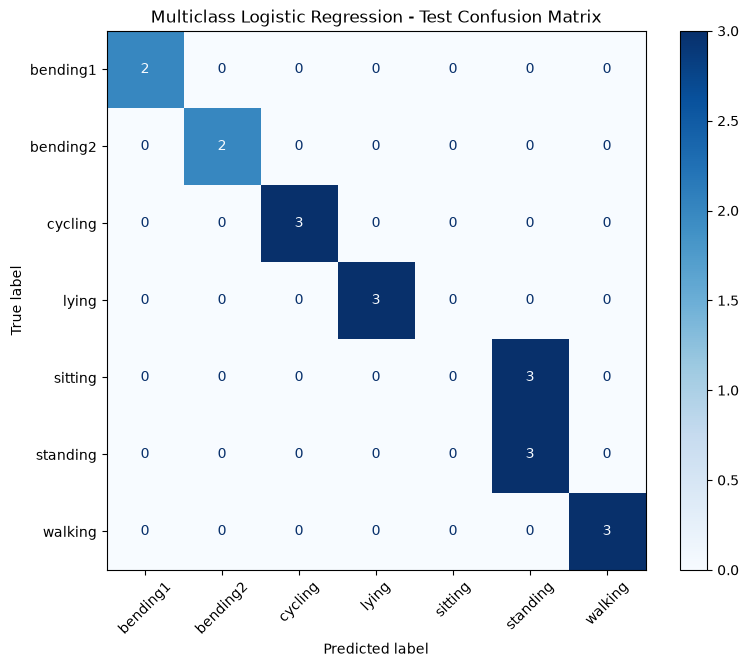

In [63]:
# Extract features
X_train_multi, y_train_multi = build_multiclass_features(
    train_files, best_l_multi
)

X_test_multi, y_test_multi = build_multiclass_features(
    test_files, best_l_multi
)

# Keep only numeric features
X_train_multi = X_train_multi.select_dtypes(include="number")
X_test_multi = X_test_multi.select_dtypes(include="number")

# Make sure training and test features match
X_test_multi = X_test_multi.reindex(columns=X_train_multi.columns)

# Replace infinite values with missing values
X_train_multi = X_train_multi.replace([np.inf, -np.inf], np.nan)
X_test_multi = X_test_multi.replace([np.inf, -np.inf], np.nan)

# Train final model
final_multi_model = clone(multi_pipeline)
final_multi_model.set_params(logistic__C=best_C_multi)

final_multi_model.fit(X_train_multi, y_train_multi)

# Predict test set
y_pred_multi = final_multi_model.predict(X_test_multi)

# Calculate accuracy
multi_test_accuracy = accuracy_score(y_test_multi, y_pred_multi)
multi_test_error = 1 - multi_test_accuracy

print("Training shape:", X_train_multi.shape)
print("Test shape:", X_test_multi.shape)
print("Best l:", best_l_multi)
print("Best C:", best_C_multi)
print("CV Accuracy:", best_cv_multi)
print("Test Accuracy:", multi_test_accuracy)
print("Test Error:", multi_test_error)

# Plot confusion matrix
cm_multi = confusion_matrix(
    y_test_multi,
    y_pred_multi,
    labels=activity_names
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_multi,
    display_labels=activity_names
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)

plt.title("Multiclass Logistic Regression - Test Confusion Matrix")
plt.show()

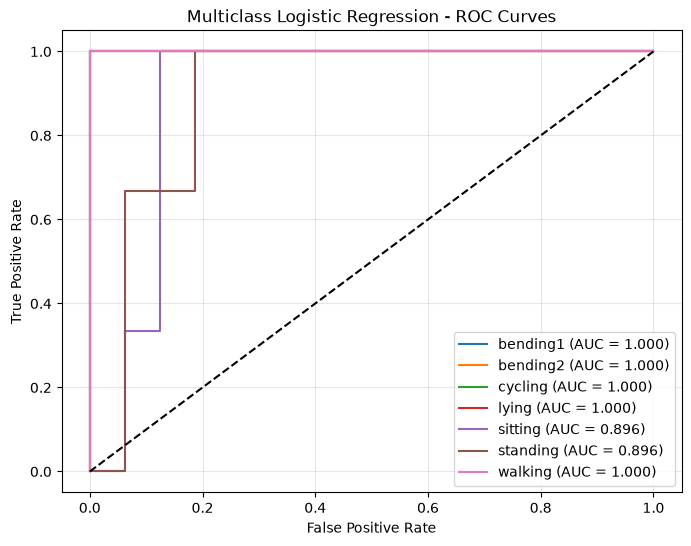

Macro Average AUC: 0.9702380952380951


In [62]:
# Get predicted probabilities
y_prob_multi = final_multi_model.predict_proba(X_test_multi)

# Get class order from the trained model
classes_multi = final_multi_model.named_steps["logistic"].classes_

# Convert true labels to binary format
y_test_bin = label_binarize(y_test_multi, classes=classes_multi)

plt.figure(figsize=(8, 6))

auc_values = []

for i, class_name in enumerate(classes_multi):
    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_prob_multi[:, i]
    )

    class_auc = auc(fpr, tpr)
    auc_values.append(class_auc)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {class_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass Logistic Regression - ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print("Macro Average AUC:", np.mean(auc_values))

#### Results and Discussion

L1-penalized multinomial logistic regression was used to classify seven human activities.

Stratified 4-fold cross-validation was used to select the number of time-series segments (l) and the regularization parameter C.

The best parameters were l = 2 and C = 0.4642.

The cross-validation accuracy was 92.81%, corresponding to an error rate of 7.19%.

The model achieved a test accuracy of 84.21% and a test error of 15.79% on 19 test instances.

The confusion matrix showed that 16 out of 19 test instances were correctly classified. All three sitting instances were incorrectly classified as standing, while the remaining classes were correctly classified.

One-vs-Rest ROC curves were generated for all seven classes. The macro-average AUC was 0.9702.

The model achieved strong overall discrimination, although it had difficulty distinguishing sitting from standing.

### 2(c)ii. Multiclass Classification Using Naive Bayes

In [64]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

gnb_results = []

gnb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GaussianNB())
])

for l in range(1, 21):
    X_l, y_l = build_multiclass_features(train_files, l)

    X_l = X_l.select_dtypes(include="number")
    X_l = X_l.replace([np.inf, -np.inf], np.nan)

    scores = cross_val_score(
        gnb_pipeline,
        X_l,
        y_l,
        cv=cv_multi,
        scoring="accuracy"
    )

    gnb_results.append({
        "l": l,
        "CV_accuracy": scores.mean(),
        "CV_error": 1 - scores.mean()
    })

gnb_results_df = pd.DataFrame(gnb_results)

gnb_results_df = gnb_results_df.sort_values(
    ["CV_accuracy", "l"],
    ascending=[False, True]
).reset_index(drop=True)

display(gnb_results_df)

best_l_gnb = int(gnb_results_df.iloc[0]["l"])
best_cv_gnb = float(gnb_results_df.iloc[0]["CV_accuracy"])

print("Best l:", best_l_gnb)
print("Best CV Accuracy:", best_cv_gnb)
print("Best CV Error:", 1 - best_cv_gnb)

,l,CV_accuracy,CV_error
0,2,0.912582,0.087418
1,1,0.855392,0.144608
2,10,0.738562,0.261438
3,8,0.736928,0.263072
4,3,0.724673,0.275327
5,4,0.723856,0.276144
6,9,0.709967,0.290033
7,7,0.709967,0.290033
8,5,0.707516,0.292484
9,11,0.707516,0.292484


Best l: 2
Best CV Accuracy: 0.9125816993464051
Best CV Error: 0.0874183006535949


Best l: 2
CV Accuracy: 0.9125816993464051
CV Error: 0.0874183006535949
Test Accuracy: 0.7368421052631579
Test Error: 0.26315789473684215


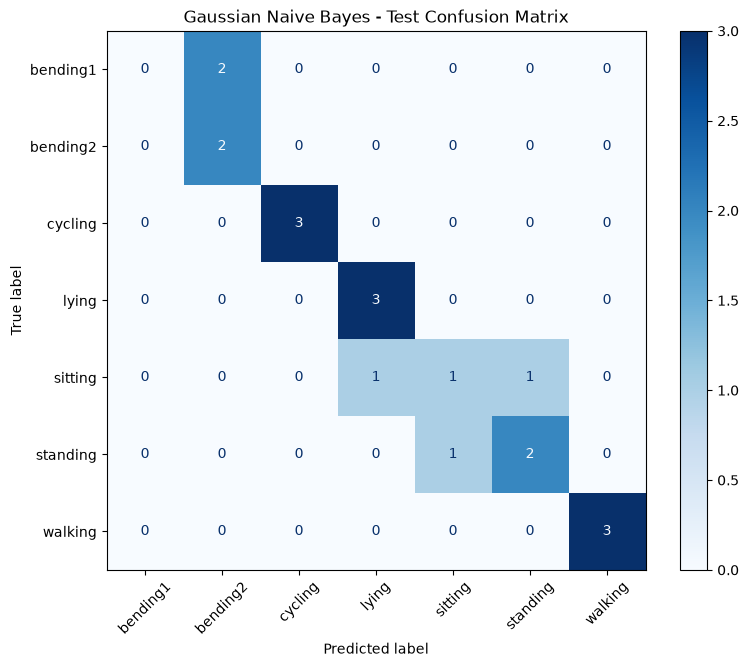

In [65]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Extract features using the best l
X_train_gnb, y_train_gnb = build_multiclass_features(
    train_files, best_l_gnb
)

X_test_gnb, y_test_gnb = build_multiclass_features(
    test_files, best_l_gnb
)

# Keep numeric features
X_train_gnb = X_train_gnb.select_dtypes(include="number")
X_test_gnb = X_test_gnb.select_dtypes(include="number")

X_test_gnb = X_test_gnb.reindex(columns=X_train_gnb.columns)

# Handle infinite values
X_train_gnb = X_train_gnb.replace([np.inf, -np.inf], np.nan)
X_test_gnb = X_test_gnb.replace([np.inf, -np.inf], np.nan)

# Train Gaussian Naive Bayes
final_gnb = clone(gnb_pipeline)
final_gnb.fit(X_train_gnb, y_train_gnb)

# Predict test set
y_pred_gnb = final_gnb.predict(X_test_gnb)

# Calculate accuracy and error
gnb_test_accuracy = accuracy_score(y_test_gnb, y_pred_gnb)
gnb_test_error = 1 - gnb_test_accuracy

print("Best l:", best_l_gnb)
print("CV Accuracy:", best_cv_gnb)
print("CV Error:", 1 - best_cv_gnb)
print("Test Accuracy:", gnb_test_accuracy)
print("Test Error:", gnb_test_error)

# Confusion matrix
cm_gnb = confusion_matrix(
    y_test_gnb,
    y_pred_gnb,
    labels=activity_names
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_gnb,
    display_labels=activity_names
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Gaussian Naive Bayes - Test Confusion Matrix")
plt.show()

In [66]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score

mnb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
    ("model", MultinomialNB())
])

mnb_results = []

for l in range(1, 21):
    X_l, y_l = build_multiclass_features(train_files, l)

    X_l = X_l.select_dtypes(include="number")
    X_l = X_l.replace([np.inf, -np.inf], np.nan)

    scores = cross_val_score(
        mnb_pipeline,
        X_l,
        y_l,
        cv=cv_multi,
        scoring="accuracy"
    )

    mnb_results.append({
        "l": l,
        "CV_accuracy": scores.mean(),
        "CV_error": 1 - scores.mean()
    })

mnb_results_df = pd.DataFrame(mnb_results)

mnb_results_df = mnb_results_df.sort_values(
    ["CV_accuracy", "l"],
    ascending=[False, True]
).reset_index(drop=True)

display(mnb_results_df)

best_l_mnb = int(mnb_results_df.iloc[0]["l"])
best_cv_mnb = float(mnb_results_df.iloc[0]["CV_accuracy"])

print("Best l:", best_l_mnb)
print("Best CV Accuracy:", best_cv_mnb)
print("Best CV Error:", 1 - best_cv_mnb)

,l,CV_accuracy,CV_error
0,1,0.825163,0.174837
1,2,0.812908,0.187092
2,7,0.781046,0.218954
3,3,0.767974,0.232026
4,4,0.754085,0.245915
5,5,0.739379,0.260621
6,8,0.725490,0.274510
7,6,0.724673,0.275327
8,10,0.723856,0.276144
9,9,0.709967,0.290033


Best l: 1
Best CV Accuracy: 0.8251633986928104
Best CV Error: 0.1748366013071896


Best l: 1
CV Accuracy: 0.8251633986928104
CV Error: 0.1748366013071896
Test Accuracy: 0.8421052631578947
Test Error: 0.1578947368421053


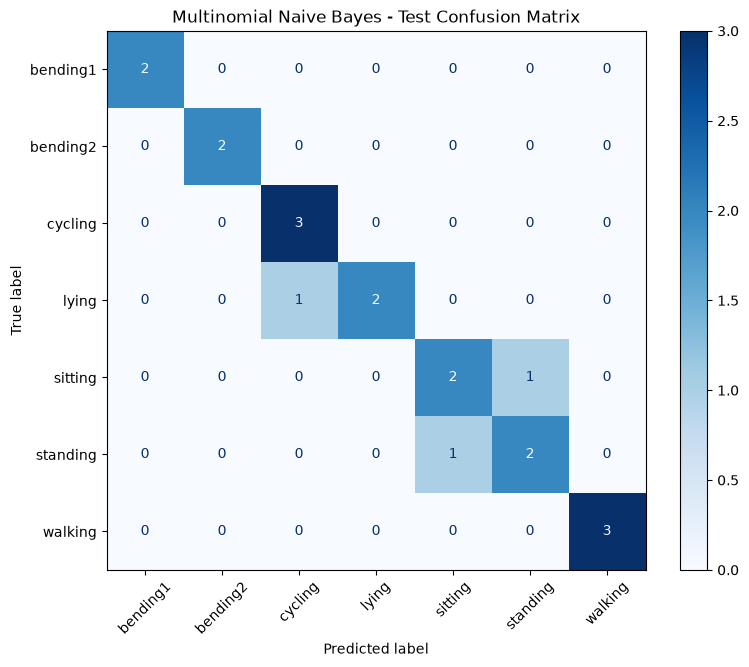

In [67]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

X_train_mnb, y_train_mnb = build_multiclass_features(
    train_files, best_l_mnb
)

X_test_mnb, y_test_mnb = build_multiclass_features(
    test_files, best_l_mnb
)

# Keep numeric features
X_train_mnb = X_train_mnb.select_dtypes(include="number")
X_test_mnb = X_test_mnb.select_dtypes(include="number")

# Match feature columns
X_test_mnb = X_test_mnb.reindex(columns=X_train_mnb.columns)

# Handle infinite values
X_train_mnb = X_train_mnb.replace([np.inf, -np.inf], np.nan)
X_test_mnb = X_test_mnb.replace([np.inf, -np.inf], np.nan)

# Train the final model
final_mnb = clone(mnb_pipeline)
final_mnb.fit(X_train_mnb, y_train_mnb)

# Predict test set
y_pred_mnb = final_mnb.predict(X_test_mnb)

# Calculate accuracy and error
mnb_test_accuracy = accuracy_score(y_test_mnb, y_pred_mnb)
mnb_test_error = 1 - mnb_test_accuracy

print("Best l:", best_l_mnb)
print("CV Accuracy:", best_cv_mnb)
print("CV Error:", 1 - best_cv_mnb)
print("Test Accuracy:", mnb_test_accuracy)
print("Test Error:", mnb_test_error)

# Confusion matrix
cm_mnb = confusion_matrix(
    y_test_mnb,
    y_pred_mnb,
    labels=activity_names
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mnb,
    display_labels=activity_names
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)

plt.title("Multinomial Naive Bayes - Test Confusion Matrix")
plt.show()

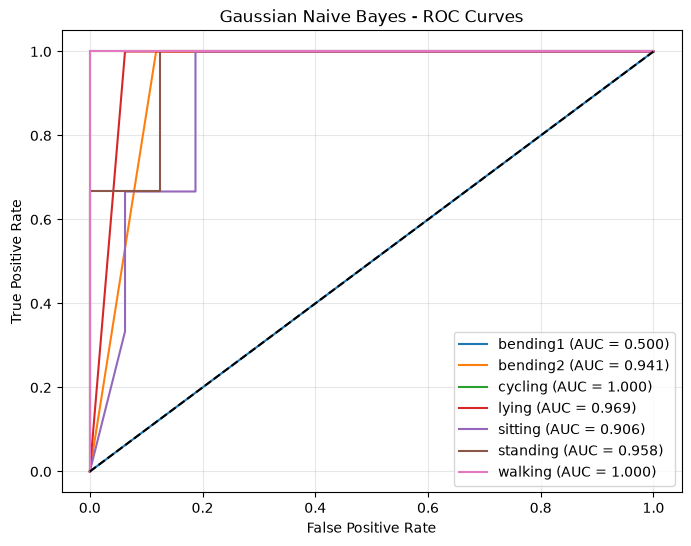

Gaussian Naive Bayes Macro Average AUC: 0.8964


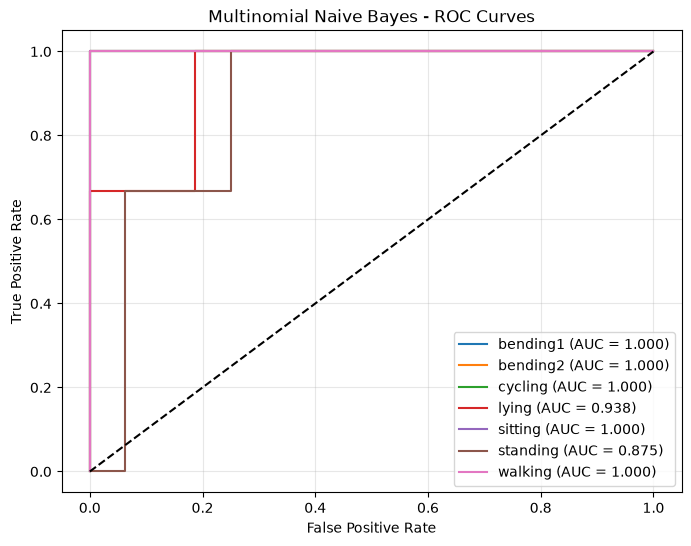

Multinomial Naive Bayes Macro Average AUC: 0.9732


In [68]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

models = [
    ("Gaussian Naive Bayes", final_gnb, X_test_gnb, y_test_gnb),
    ("Multinomial Naive Bayes", final_mnb, X_test_mnb, y_test_mnb)
]

for title, model, X_test, y_test in models:

    probabilities = model.predict_proba(X_test)
    classes = model.classes_
    y_binary = label_binarize(y_test, classes=classes)

    plt.figure(figsize=(8, 6))

    auc_scores = []

    for i, activity in enumerate(classes):

        fpr, tpr, _ = roc_curve(
            y_binary[:, i],
            probabilities[:, i]
        )

        score = auc(fpr, tpr)
        auc_scores.append(score)

        plt.plot(
            fpr,
            tpr,
            label=f"{activity} (AUC = {score:.3f})"
        )

    plt.plot([0, 1], [0, 1], "k--")

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{title} - ROC Curves")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

    print(f"{title} Macro Average AUC: {sum(auc_scores)/len(auc_scores):.4f}")

#### Results and Discussion

Gaussian Naive Bayes and Multinomial Naive Bayes were compared using stratified 4-fold cross-validation.

Gaussian NB selected l = 2, with a CV error of 8.74% and a test error of 26.32%.

Multinomial NB selected l = 1, with a CV error of 17.48% and a test error of 15.79%.

Gaussian NB performed better in cross-validation, while Multinomial NB achieved a lower test error.

Both models had difficulty distinguishing some activities, especially sitting and standing.

Since the features are continuous statistics rather than count data, Gaussian NB is theoretically more suitable for this dataset. However, Multinomial NB performed better on the test set in this experiment.

### 2(c)iii. Comparison

L1-penalized multinomial logistic regression has the lowest cross-validation error (7.19%), followed by Gaussian NB (8.74%) and Multinomial NB (17.48%).

On the test set, L1 logistic regression and Multinomial NB both achieve an error of 15.79%, while Gaussian NB has a higher error of 26.32%.

Overall, I would choose L1-penalized logistic regression because it has the lowest cross-validation error and performs equally well as the best model on the test set.

### 3. ISLR 4.8.3

For QDA, assume that the observations in class k follow a normal distribution:

$$
X \mid Y=k \sim N(\mu_k,\sigma_k^2)
$$

The class-conditional density is:

$$
f_k(x)=\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)
$$

The Bayes classifier assigns an observation to the class that maximizes:

$$
\pi_k f_k(x)
$$

Taking the logarithm and removing the constant term gives:

$$
\delta_k(x)=\log\pi_k-\log\sigma_k
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
$$

Expanding the squared term:

$$
\delta_k(x)=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\log\sigma_k+\log\pi_k
$$

Since the variances can differ across classes, the coefficient of the quadratic term depends on k.

When the class variances differ, the quadratic terms generally do not cancel, resulting in a quadratic decision rule, and the resulting classifier is generally quadratic. This is the basis of Quadratic Discriminant Analysis (QDA).

If all classes have the same variance, the quadratic terms cancel when comparing discriminant functions, resulting in a linear decision rule (LDA).

However, when the variances differ, the quadratic terms do not cancel. The decision boundary between classes k and l is determined by:

$$
\delta_k(x)=\delta_l(x)
$$

Since the difference between these discriminant functions contains a nonzero quadratic term, the decision boundary is determined by a quadratic equation.

### 4. ISLR 4.8.7

We are given $P(Yes)=0.8$, $P(No)=0.2$, $\mu_{Yes}=10$, $\mu_{No}=0$, and $\sigma^2=36$.

Using Bayes' theorem, the probability that a company issues a dividend given $X=4$ is:

$$
P(Y=Yes\mid X=4)
=
\frac{0.8e^{-\frac{(4-10)^2}{2(36)}}}
{0.8e^{-\frac{(4-10)^2}{2(36)}}+
0.2e^{-\frac{(4-0)^2}{2(36)}}}
$$

$$
=
\frac{0.8e^{-1/2}}
{0.8e^{-1/2}+0.2e^{-2/9}}
\approx 0.752
$$

Therefore, the probability that the company will issue a dividend this year is approximately 75.2%.